# 10 · 설비 예지보수와 장애 예측
### 실습으로 배우는 GMP AI — 강의 목차 ⑪ 설비 예지보수와 장애 예측

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/StillWork/GMPAI/blob/main/10_Predictive_Maintenance_RUL.ipynb)

| 항목 | 내용 |
|---|---|
| **학습 목표** | ① 보전 전략 비교(사후·예방·**예지**) ② **RUL(잔여 유효 수명)** 개념과 레이블 설계 ③ 열화 신호 특성공학 ④ RUL 회귀 + 고장 임박 분류 ⑤ **비용 기반 정비 시점** 결정 ⑥ 제약 설비 적용 |
| **데이터** | **NASA C-MAPSS FD001** — 터보팬 엔진 100대의 전 생애 센서 기록 (예지보수 연구의 국제 표준 벤치마크) |
| **실행 환경** | CPU · 약 10분 |

> 제약 설비(동결건조기·멸균기·충전기·HVAC)도 **"센서 신호가 서서히 변하다가 고장난다"** 는 구조가 같습니다.
> 공개 벤치마크로 기법을 익히고, 사내 설비 데이터에 그대로 옮기는 것이 현실적인 접근입니다.

In [1]:
%pip install -q koreanize-matplotlib
import koreanize_matplotlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time
import warnings; warnings.filterwarnings("ignore")
BASE = "https://raw.githubusercontent.com/StillWork/data/refs/heads/master/"
cols = ["unit", "cycle"] + [f"op{i}" for i in range(1, 4)] + [f"s{i}" for i in range(1, 22)]
train = pd.read_csv(BASE + "train_FD001.txt", sep=r"\s+", header=None, names=cols)
test = pd.read_csv(BASE + "test_FD001.txt", sep=r"\s+", header=None, names=cols)
rul_true = pd.read_csv(BASE + "RUL_FD001.txt", header=None, names=["RUL"])["RUL"].values
print(f"학습: 설비 {train.unit.nunique()}대, {len(train):,}사이클 (전부 고장까지 운전)")
print(f"시험: 설비 {test.unit.nunique()}대, {len(test):,}사이클 (운전 중간까지만 — 남은 수명을 맞혀야 함)")
train.head(3)

Note: you may need to restart the kernel to use updated packages.


학습: 설비 100대, 20,631사이클 (전부 고장까지 운전)
시험: 설비 100대, 13,096사이클 (운전 중간까지만 — 남은 수명을 맞혀야 함)


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


## 1. 보전(Maintenance) 전략 — 왜 예지보수인가
| 전략 | 방식 | 장점 | 단점 | GMP 영향 |
|---|---|---|---|---|
| **사후 보전** (Reactive) | 고장 나면 고친다 | 비용 최소(겉보기) | 생산 중단, **배치 손실** | 일탈·조사 발생 |
| **예방 보전** (Preventive) | 정해진 주기마다 교체 | 단순, 관리 쉬움 | 멀쩡한 부품 교체(과잉), 그래도 고장 발생 | 적격성 재수행 부담 |
| **예지 보전** (Predictive) | **상태를 감시해 필요할 때** | 다운타임·비용↓ | 센서·모델·검증 필요 | **배치 중 고장 예방** |

> **제약 현장의 특수성**: 배치 중 설비가 멈추면 **그 배치 전체가 일탈** 대상입니다.
> 생물의약품은 배치 하나가 수억~수십억 원이므로, 고장 1건 예방의 가치가 매우 큽니다.
> 또한 설비 변경·수리 후에는 **적격성(IQ/OQ/PQ) 재확인**이 필요하므로 **계획된 정비**가 훨씬 유리합니다.

## 2. RUL(Remaining Useful Life) — 레이블 설계가 핵심
학습 데이터는 설비가 **고장날 때까지** 운전한 기록이므로, 각 시점의 RUL = (고장 사이클 − 현재 사이클) 로 계산합니다.

⭐ **중요**: 초기에는 열화 신호가 거의 없어 "남은 수명 300"과 "250"을 구분할 수 없습니다.
→ 업계 표준은 **상한을 두는 조각별 선형(piecewise linear) RUL** (보통 125): "충분히 건강함"과 "열화 진행 중"을 구분.

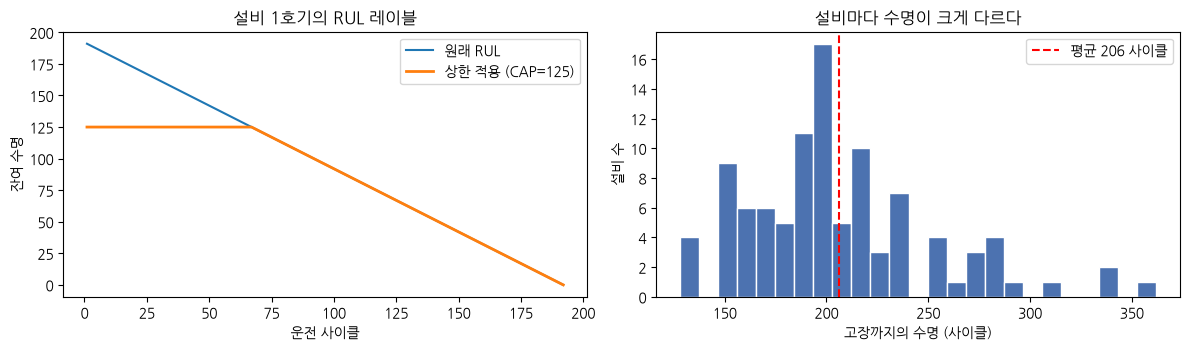

수명 범위: 128 ~ 362 사이클 → 고정 주기 예방보전이 비효율적인 이유


In [2]:
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
CAP = 125
train["RUL_capped"] = train["RUL"].clip(upper=CAP)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
u = train[train.unit == 1]
ax[0].plot(u.cycle, u.RUL, label="원래 RUL"); ax[0].plot(u.cycle, u.RUL_capped, lw=2, label=f"상한 적용 (CAP={CAP})")
ax[0].set_xlabel("운전 사이클"); ax[0].set_ylabel("잔여 수명"); ax[0].legend(); ax[0].set_title("설비 1호기의 RUL 레이블")
life = train.groupby("unit").cycle.max()
ax[1].hist(life, bins=25, color="#4C72B0", edgecolor="white")
ax[1].axvline(life.mean(), color="red", ls="--", label=f"평균 {life.mean():.0f} 사이클")
ax[1].set_xlabel("고장까지의 수명 (사이클)"); ax[1].set_ylabel("설비 수"); ax[1].legend(); ax[1].set_title("설비마다 수명이 크게 다르다")
plt.tight_layout(); plt.show()
print(f"수명 범위: {life.min()} ~ {life.max()} 사이클 → 고정 주기 예방보전이 비효율적인 이유")

변동이 없는 센서 6개 제외: ['s1', 's5', 's10', 's16', 's18', 's19']


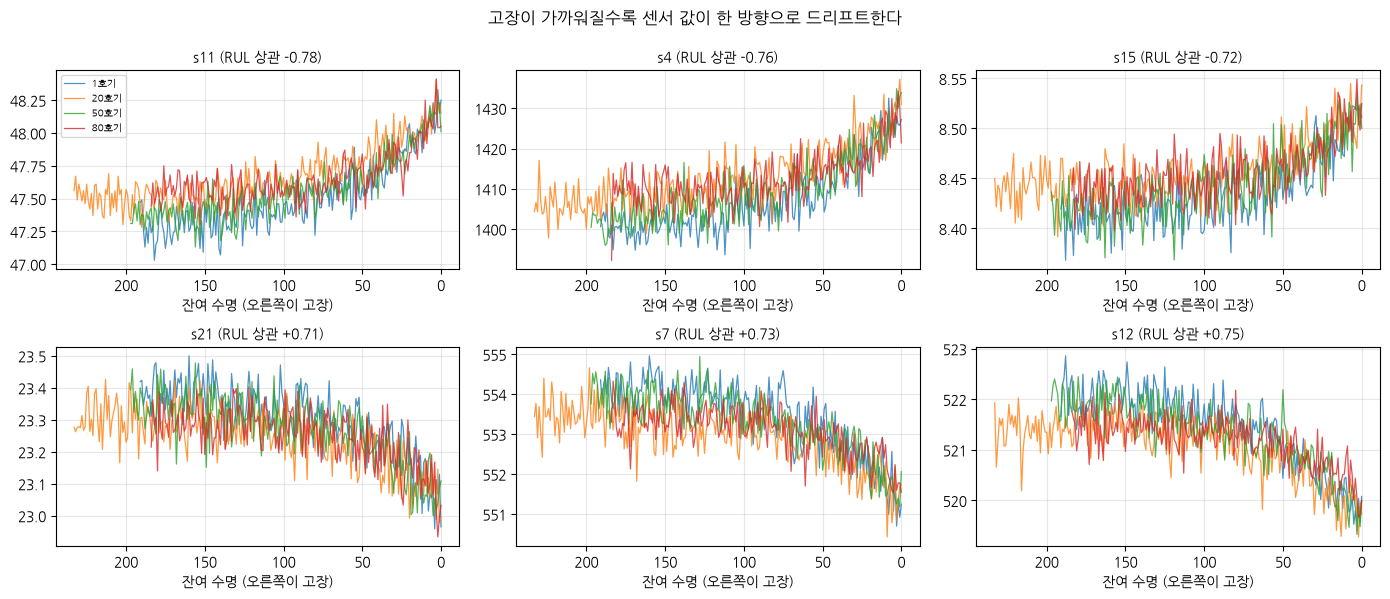

In [3]:
# 센서 신호의 열화 추세 — 고장이 다가올수록 특정 센서가 서서히 변한다
const = [c for c in cols if c.startswith("s") and train[c].std() < 1e-6]
sensors = [c for c in cols if c.startswith("s") and c not in const]
print(f"변동이 없는 센서 {len(const)}개 제외: {const}")
corr = train[sensors].corrwith(train["RUL_capped"]).sort_values()
show = list(corr.index[:3]) + list(corr.index[-3:])
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for a, c in zip(ax.ravel(), show):
    for u_ in [1, 20, 50, 80]:
        g = train[train.unit == u_]
        a.plot(g.RUL, g[c], lw=0.9, alpha=0.8, label=f"{u_}호기")
    a.invert_xaxis(); a.set_xlabel("잔여 수명 (오른쪽이 고장)"); a.set_title(f"{c} (RUL 상관 {corr[c]:+.2f})", fontsize=10); a.grid(alpha=0.3)
ax[0, 0].legend(fontsize=7)
plt.suptitle("고장이 가까워질수록 센서 값이 한 방향으로 드리프트한다", y=0.99); plt.tight_layout(); plt.show()

## 3. 특성공학 — 순간값보다 '추세'가 중요하다
센서 1회 측정값은 노이즈가 큽니다. **이동평균(수준)** 과 **기울기(변화 속도)** 를 함께 주면 모델이 열화를 훨씬 잘 봅니다.

In [4]:
WIN = 20
def make_features(d, win=WIN):
    out = d[["unit", "cycle"]].copy()
    for c in sensors + ["op1", "op2", "op3"]:
        out[c] = d[c]
        out[c + "_이동평균"] = d.groupby("unit")[c].transform(lambda s: s.rolling(win, min_periods=1).mean())
        out[c + "_변화율"] = d.groupby("unit")[c].transform(lambda s: s.diff().rolling(win, min_periods=1).mean()).fillna(0)
    return out

t = time.time()
F_train, F_test = make_features(train), make_features(test)
print(f"특성 {F_train.shape[1]-1}개 생성 ({time.time()-t:.0f}초)")

특성 55개 생성 (0초)


## 4. RUL 회귀 — 설비 단위 교차검증
예제 09와 같은 원칙: **한 설비의 데이터가 학습·평가에 나뉘면 안 됩니다** → `GroupKFold(groups=unit)`

In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error

X, y, g = F_train.drop(columns=["unit"]), train["RUL_capped"], train["unit"]
rf = RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=0, min_samples_leaf=5)
t = time.time()
pred_cv = cross_val_predict(rf, X, y, cv=GroupKFold(5), groups=g)
print(f"설비 단위 5-겹 CV:  R² = {r2_score(y, pred_cv):.3f}   MAE = {mean_absolute_error(y, pred_cv):.1f} 사이클  ({time.time()-t:.0f}초)")

# 한 번도 보지 않은 시험 설비 100대의 '마지막 시점'에서 남은 수명 예측
rf.fit(X, y)
last = F_test.groupby("unit").tail(1)
pred_test = rf.predict(last.drop(columns=["unit"]))
true_test = np.clip(rul_true, 0, CAP)
print(f"시험 설비 100대:     R² = {r2_score(true_test, pred_test):.3f}   MAE = {mean_absolute_error(true_test, pred_test):.1f} 사이클   "
      f"RMSE = {np.sqrt(((true_test - pred_test)**2).mean()):.1f}")

설비 단위 5-겹 CV:  R² = 0.831   MAE = 11.5 사이클  (51초)


시험 설비 100대:     R² = 0.810   MAE = 12.5 사이클   RMSE = 17.5


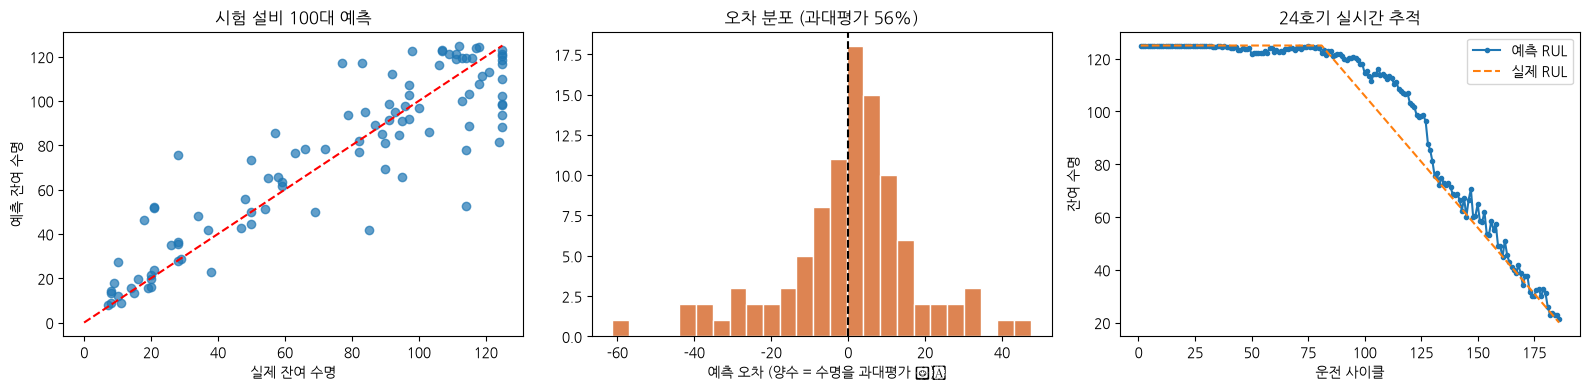

⚠️ 수명을 과대평가하는 오차(양수)가 더 위험합니다 — 정비 전에 고장이 날 수 있기 때문입니다.


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(true_test, pred_test, alpha=0.7)
ax[0].plot([0, CAP], [0, CAP], "r--"); ax[0].set_xlabel("실제 잔여 수명"); ax[0].set_ylabel("예측 잔여 수명"); ax[0].set_title("시험 설비 100대 예측")
err = pred_test - true_test
ax[1].hist(err, bins=25, color="#DD8452", edgecolor="white"); ax[1].axvline(0, color="k", ls="--")
ax[1].set_xlabel("예측 오차 (양수 = 수명을 과대평가 ⚠️)"); ax[1].set_title(f"오차 분포 (과대평가 {(err>0).mean():.0%})")
u_ = 24
gi = F_test[F_test.unit == u_]
traj = rf.predict(gi.drop(columns=["unit"]))
ax[2].plot(gi.cycle, traj, "o-", ms=3, label="예측 RUL")
ax[2].plot(gi.cycle, np.clip(rul_true[u_-1] + (gi.cycle.max() - gi.cycle), 0, CAP), "--", label="실제 RUL")
ax[2].set_xlabel("운전 사이클"); ax[2].set_ylabel("잔여 수명"); ax[2].legend(); ax[2].set_title(f"{u_}호기 실시간 추적")
plt.tight_layout(); plt.show()
print("⚠️ 수명을 과대평가하는 오차(양수)가 더 위험합니다 — 정비 전에 고장이 날 수 있기 때문입니다.")

> **비대칭 평가**: 예지보수에서는 **늦은 예측(과대평가)** 이 **이른 예측**보다 훨씬 위험합니다.
> NASA 벤치마크의 공식 점수 함수도 늦은 예측에 더 큰 벌점을 줍니다.

In [7]:
def nasa_score(y_true, y_pred):
    d = y_pred - y_true                                  # 양수 = 늦은 예측(과대평가)
    return np.sum(np.where(d < 0, np.exp(-d/13) - 1, np.exp(d/10) - 1))
print(f"NASA 점수(낮을수록 좋음) = {nasa_score(true_test, pred_test):.0f}")
print(f"  같은 크기 오차라도 늦은 예측이 더 큰 벌점: 오차 +20 → {np.exp(20/10)-1:.1f},  오차 -20 → {np.exp(20/13)-1:.1f}")

NASA 점수(낮을수록 좋음) = 623
  같은 크기 오차라도 늦은 예측이 더 큰 벌점: 오차 +20 → 6.4,  오차 -20 → 3.7


## 5. 고장 임박 분류 — "30 사이클 안에 고장날 설비는?"
회귀값(RUL)보다 **"지금 정비 계획을 세워야 하는가"** 라는 이진 판단이 현장에서 더 쓰기 쉽습니다.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
HORIZON = 30
y_cls = (train["RUL"] <= HORIZON).astype(int)
proba_cv = cross_val_predict(RandomForestClassifier(200, n_jobs=-1, random_state=0, class_weight="balanced"),
                             X, y_cls, cv=GroupKFold(5), groups=g, method="predict_proba")[:, 1]
print(f"{HORIZON}사이클 내 고장 예측 — ROC-AUC = {roc_auc_score(y_cls, proba_cv):.3f}, "
      f"PR-AUC = {average_precision_score(y_cls, proba_cv):.3f} (양성 비율 {y_cls.mean():.1%})")
print(classification_report(y_cls, (proba_cv >= 0.5).astype(int), target_names=["여유 있음", "고장 임박"], digits=3))

30사이클 내 고장 예측 — ROC-AUC = 0.990, PR-AUC = 0.953 (양성 비율 15.0%)
              precision    recall  f1-score   support

       여유 있음      0.981     0.971     0.976     17531
       고장 임박      0.845     0.896     0.870      3100

    accuracy                          0.960     20631
   macro avg      0.913     0.934     0.923     20631
weighted avg      0.961     0.960     0.960     20631



## 6. ⭐ 비용 기반 정비 시점 결정
| 상황 | 비용 |
|---|---|
| **계획 정비** (고장 전 교체) | 부품비 + 계획된 다운타임 → 상대비용 **1** |
| **고장 발생** (배치 중 정지) | 배치 손실 + 긴급 수리 + 일탈 조사 + 적격성 재수행 → 상대비용 **20** |
| **너무 이른 교체** | 남은 수명을 버림 → 낭비 비용 |

In [9]:
# 정비 정책 시뮬레이션은 '고장까지 운전한' 학습 설비 100대로 수행합니다.
# (시험 설비는 중간에 기록이 끊겨 있어 정책 평가에 부적합합니다)
# 예측값은 교차검증 예측(pred_cv)을 사용 — 자기 설비 데이터로 학습한 모델을 쓰지 않도록
sim = []
for u_, gi in train.assign(pred=pred_cv).groupby("unit"):
    gi = gi.sort_values("cycle")
    sim.append({"unit": u_, "pred": gi["pred"].values, "true": gi["RUL"].values, "life": gi["cycle"].max()})
print(f"고장까지 운전한 설비 {len(sim)}대로 정비 정책을 시뮬레이션합니다.")
print(f"평균 수명 {np.mean([s_['life'] for s_ in sim]):.0f} 사이클")

고장까지 운전한 설비 100대로 정비 정책을 시뮬레이션합니다.
평균 수명 206 사이클


,정비 착수 기준,계획 정비,고장 발생,버린 잔여수명(합),총 비용
0,5,86,14,380.0,373.6
1,10,100,0,884.0,117.7
2,15,100,0,1425.0,128.5
3,20,100,0,1901.0,138.0
4,30,100,0,2860.0,157.2
5,40,100,0,3839.0,176.8
6,50,100,0,4854.0,197.1
7,70,100,0,7502.0,250.0
8,90,100,0,10169.0,303.4


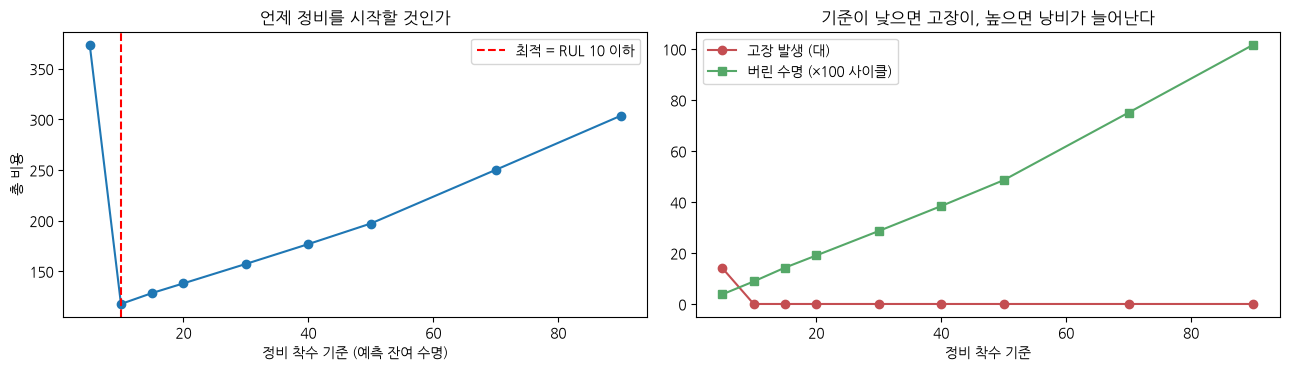

→ 고장 비용이 계획 정비의 20배일 때 최적 기준은 예측 RUL 10 이하


In [10]:
C_PLANNED, C_FAILURE, C_WASTE = 1.0, 20.0, 0.02      # 계획정비 / 고장 / 잔여수명 1사이클 폐기

def simulate_predictive(threshold):
    planned = failed = 0; wasted = 0.0
    for s_ in sim:
        hit = np.where(s_["pred"] <= threshold)[0]
        if len(hit) == 0 or s_["true"][hit[0]] <= 0:
            failed += 1                                     # 경보가 없었거나 이미 늦음 → 고장
        else:
            planned += 1; wasted += s_["true"][hit[0]]      # 계획 정비 + 버린 잔여수명
    return {"정비 착수 기준": threshold, "계획 정비": planned, "고장 발생": failed,
            "버린 잔여수명(합)": wasted,
            "총 비용": C_PLANNED * planned + C_FAILURE * failed + C_WASTE * wasted}

cost_df = pd.DataFrame([simulate_predictive(th) for th in [5, 10, 15, 20, 30, 40, 50, 70, 90]])
best = cost_df.loc[cost_df["총 비용"].idxmin()]
display(cost_df.round(1))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(cost_df["정비 착수 기준"], cost_df["총 비용"], "o-")
ax[0].axvline(best["정비 착수 기준"], color="red", ls="--", label=f"최적 = RUL {best['정비 착수 기준']:.0f} 이하")
ax[0].set_xlabel("정비 착수 기준 (예측 잔여 수명)"); ax[0].set_ylabel("총 비용"); ax[0].legend(); ax[0].set_title("언제 정비를 시작할 것인가")
ax[1].plot(cost_df["정비 착수 기준"], cost_df["고장 발생"], "o-", color="#C44E52", label="고장 발생 (대)")
ax[1].plot(cost_df["정비 착수 기준"], cost_df["버린 잔여수명(합)"] / 100, "s-", color="#55A868", label="버린 수명 (×100 사이클)")
ax[1].set_xlabel("정비 착수 기준"); ax[1].legend(); ax[1].set_title("기준이 낮으면 고장이, 높으면 낭비가 늘어난다")
plt.tight_layout(); plt.show()
print(f"→ 고장 비용이 계획 정비의 {C_FAILURE:.0f}배일 때 최적 기준은 예측 RUL {best['정비 착수 기준']:.0f} 이하")

,정비 주기,계획 정비,고장 발생,버린 잔여수명(합),총 비용
0,100,100,0,10631.0,312.6
1,120,100,0,8631.0,272.6
2,130,99,1,7633.0,271.7
3,140,96,4,6654.0,309.1
4,150,93,7,5700.0,347.0
5,170,77,23,3993.0,616.9
6,190,63,37,2561.0,854.2
7,210,37,63,1586.0,1328.7


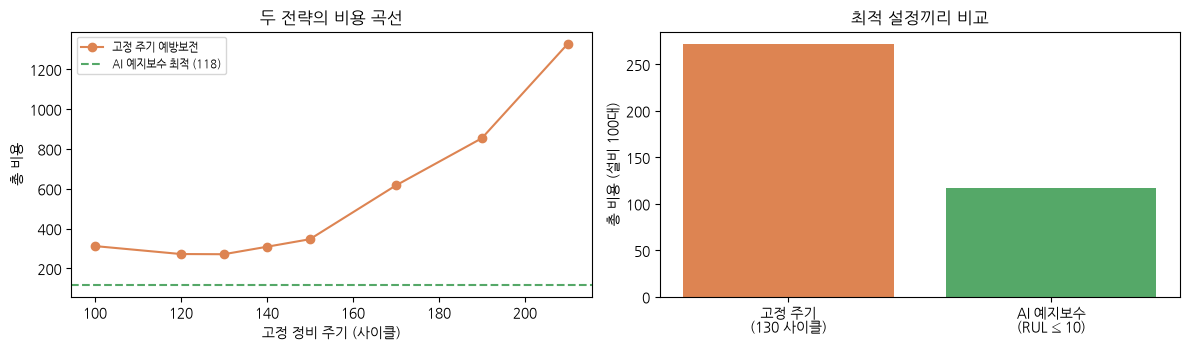

고정 주기 최적: 비용 272 (고장 1대, 버린 수명 7633사이클)
AI 예지보수  : 비용 118 (고장 0대, 버린 수명 884사이클)
※ 비용 가정(고장 20배)에 따라 결과가 달라집니다. 도입 전 사내 비용 데이터로 다시 계산해야 합니다.


In [11]:
# 전략 비교: 고정 주기 예방보전 vs AI 예지보수 (같은 설비 100대, 같은 비용 가정)
def simulate_fixed(interval):
    planned = failed = 0; wasted = 0.0
    for s_ in sim:
        if interval >= s_["life"]: failed += 1               # 정비 전에 고장
        else: planned += 1; wasted += s_["life"] - interval  # 남은 수명을 버리고 교체
    return {"정비 주기": interval, "계획 정비": planned, "고장 발생": failed,
            "버린 잔여수명(합)": wasted,
            "총 비용": C_PLANNED * planned + C_FAILURE * failed + C_WASTE * wasted}

fixed_df = pd.DataFrame([simulate_fixed(iv) for iv in [100, 120, 130, 140, 150, 170, 190, 210]])
best_fixed = fixed_df.loc[fixed_df["총 비용"].idxmin()]
display(fixed_df.round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(fixed_df["정비 주기"], fixed_df["총 비용"], "o-", color="#DD8452", label="고정 주기 예방보전")
ax[0].axhline(best["총 비용"], color="#55A868", ls="--", label=f"AI 예지보수 최적 ({best['총 비용']:.0f})")
ax[0].set_xlabel("고정 정비 주기 (사이클)"); ax[0].set_ylabel("총 비용"); ax[0].legend(fontsize=8); ax[0].set_title("두 전략의 비용 곡선")
ax[1].bar([f"고정 주기\n({best_fixed['정비 주기']:.0f} 사이클)", f"AI 예지보수\n(RUL ≤ {best['정비 착수 기준']:.0f})"],
          [best_fixed["총 비용"], best["총 비용"]], color=["#DD8452", "#55A868"])
ax[1].set_ylabel("총 비용 (설비 100대)"); ax[1].set_title("최적 설정끼리 비교")
plt.tight_layout(); plt.show()
print(f"고정 주기 최적: 비용 {best_fixed['총 비용']:.0f} (고장 {best_fixed['고장 발생']:.0f}대, 버린 수명 {best_fixed['버린 잔여수명(합)']:.0f}사이클)")
print(f"AI 예지보수  : 비용 {best['총 비용']:.0f} (고장 {best['고장 발생']:.0f}대, 버린 수명 {best['버린 잔여수명(합)']:.0f}사이클)")
print("※ 비용 가정(고장 20배)에 따라 결과가 달라집니다. 도입 전 사내 비용 데이터로 다시 계산해야 합니다.")

## 7. 제약 설비에 어떻게 적용하나
| 설비 | 감시 센서 | 고장 징후 | 배치 영향 |
|---|---|---|---|
| **동결건조기** | 진공압, 콘덴서 온도, 냉동기 전류 | 진공 도달 시간 증가, 콘덴서 온도 상승 | 배치 전량 손실 가능 |
| **멸균기(오토클레이브)** | 챔버 압력·온도, 밸브 응답 | 승온 시간 증가, F0 편차 | 무균성 보증 실패 |
| **충전기** | 노즐 압력, 모터 전류, 중량 편차 | 중량 RSD 증가, 토크 변화 | 함량 균일성 일탈 |
| **HVAC** | 차압, 필터 차압, 팬 전류 | 필터 차압 상승 | 환경 등급 이탈 |
| **정제수(WFI)** | TOC, 전도도, 유량, 펌프 전류 | 전도도 상승 추세 | 전 공정 영향 |

### 도입 순서
1. **데이터 수집 체계**: Historian 에 센서 데이터 저장 (최소 1~2년, 고장 이력 포함)
2. **고장 이력 정비**: 정비 기록(CMMS)과 센서 데이터를 **시간 기준으로 연결** ← 보통 여기가 가장 어렵습니다
3. **기준선**: 단순 임계값·추세 감시부터 (예제 03의 SPC)
4. **모델**: 고장 사례가 쌓이면 RUL 회귀·임박 분류
5. **검증·운영**: 예측 성능 모니터링, 정비 결정 절차 문서화 (예제 11)

> ⚠️ **현실 조언**: 대부분의 공장은 "고장 데이터가 부족"합니다. 고장이 드물기 때문입니다.
> 처음에는 **이상탐지(예제 06)** 로 시작해 "평소와 다름"을 잡고, 고장 사례를 축적하며 RUL 모델로 발전시키는 것이 현실적입니다.

## 🧪 LLM 코딩 과제
```
train(C-MAPSS, 열: unit, cycle, s1~s21, RUL), F_train(특성), rf(학습된 모델)이 있어.
예측 구간(predict interval)을 만들어줘: RandomForest 의 개별 트리 예측 분포에서 10/90 분위수를 구해서
시험 설비 10대의 예측 RUL 과 불확실성 구간을 오차막대 그래프로 보여줘. 한글 주석을 달아줘.
```

In [12]:
# ✏️ LLM 코딩 과제 코드 붙여넣기

## ✅ 정리
| 개념 | 핵심 |
|---|---|
| 보전 전략 | 제약은 **배치 손실 비용**이 커서 예지보수의 가치가 큼 |
| RUL 레이블 | **상한을 둔 조각별 선형 RUL** 이 표준 (초기에는 열화 신호가 없음) |
| 특성공학 | 순간값보다 **이동평균·변화율(추세)** |
| 검증 | **설비 단위 분리** 교차검증 |
| 비대칭 오차 | **늦은 예측(수명 과대평가)** 이 훨씬 위험 → NASA 점수 같은 비대칭 지표 |
| 의사결정 | 모델 출력 → **비용 기반 정비 임계값** → 정비 계획 |

➡️ **다음 예제 11 (최종)**: 만든 모델을 GMP 환경에 올리기 — **검증·감사추적·드리프트 관리와 규제 대응**